In [ ]:
!pip install "gymnasium[classic-control]" moviepy

In [ ]:
!pip install gymnasium[classic]
!pip install gymnasium[box2d]
!pip install collection
!pip install itertools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 21.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 46.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pygame-ce]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for collection: filename=collection-0.1.6-py3-none-any.whl size=5148 sha256=d80fcabb560635d79e140a0ed75454b13ff598881129dc545d33725e21cb58dd
  Stored in directory: /root/.cache/pip/wheels/44/4e/bc/c84bc8b82a0f294305b47c7ff1ffcda2e15cc9ca2b175ba674
Successfully built collection
ERROR: Could not find a version that satisfies the requirement itertools (from versions: none)
ERROR: No matching distribution found for itertools


Complete


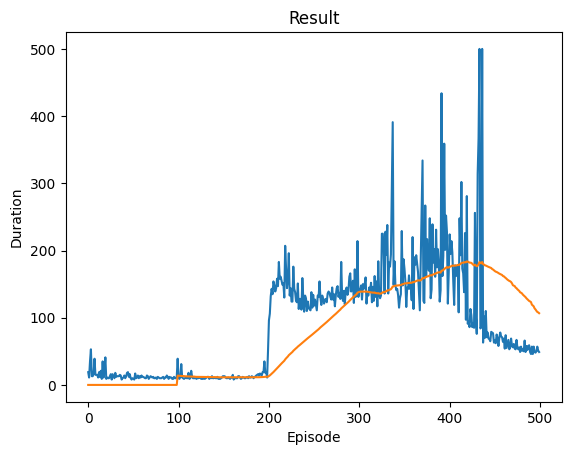

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [ ]:
import gymnasium as gym
import math
import random
import matplotlib
import matplotlib.pyplot as plt

from collections import namedtuple, deque
from itertools import count

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F


# ==========================================
# 1. ENVIRONMENT SETUP
# ==========================================

env = gym.make("CartPole-v1")

is_ipython = 'inline' in matplotlib.get_backend()

if is_ipython:
    from IPython import display

plt.ion()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Using device: {device}")


# ==========================================
# 2. REPLAY MEMORY
# ==========================================

Transition = namedtuple(
    'Transition',
    ('state', 'action', 'next_state', 'reward')
)


class ReplayMemory:

    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        """Save a transition."""
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        """Randomly sample transitions."""
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)


# ==========================================
# 3. DEEP Q-NETWORK
# ==========================================

class DQN(nn.Module):

    def __init__(self, n_observations, n_actions):
        super(DQN, self).__init__()

        self.layer1 = nn.Linear(n_observations, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, n_actions)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))

        return self.layer3(x)


# ==========================================
# 4. HYPERPARAMETERS
# ==========================================

BATCH_SIZE = 128
GAMMA = 0.99

EPS_START = 0.9
EPS_END = 0.05
EPS_DECAY = 1000

TAU = 0.005
LR = 1e-4


# ==========================================
# 5. INITIALISE NETWORKS
# ==========================================

n_actions = env.action_space.n

state, info = env.reset()

n_observations = len(state)

policy_net = DQN(
    n_observations,
    n_actions
).to(device)

target_net = DQN(
    n_observations,
    n_actions
).to(device)

target_net.load_state_dict(policy_net.state_dict())

optimizer = optim.AdamW(
    policy_net.parameters(),
    lr=LR,
    amsgrad=True
)

memory = ReplayMemory(10000)


# ==========================================
# 6. ACTION SELECTION (EPSILON-GREEDY)
# ==========================================

steps_done = 0


def select_action(state):

    global steps_done

    sample = random.random()

    eps_threshold = EPS_END + (
        EPS_START - EPS_END
    ) * math.exp(-1. * steps_done / EPS_DECAY)

    steps_done += 1

    if sample > eps_threshold:

        with torch.no_grad():
            return policy_net(state).max(1)[1].view(1, 1)

    else:

        return torch.tensor(
            [[env.action_space.sample()]],
            dtype=torch.long,
            device=device
        )


# ==========================================
# 7. PLOT TRAINING PROGRESS
# ==========================================

episode_durations = []


def plot_durations(show_result=False):

    plt.figure(1)

    duration_t = torch.tensor(
        episode_durations,
        dtype=torch.float
    )

    if show_result:
        plt.title('Result')
    else:
        plt.clf()
        plt.title('Training...')

    plt.xlabel('Episode')
    plt.ylabel('Duration')

    plt.plot(duration_t.numpy())

    if len(duration_t) >= 100:

        means = duration_t.unfold(
            0, 100, 1
        ).mean(1).view(-1)

        means = torch.cat((
            torch.zeros(99),
            means
        ))

        plt.plot(means.numpy())

    plt.pause(0.001)

    if is_ipython:

        if not show_result:
            display.display(plt.gcf())
            display.clear_output(wait=True)

        else:
            display.display(plt.gcf())


# ==========================================
# 8. OPTIMISE THE POLICY NETWORK
# ==========================================

def optimize_mode():

    if len(memory) < BATCH_SIZE:
        return

    transitions = memory.sample(BATCH_SIZE)

    batch = Transition(*zip(*transitions))

    # Identify non-terminal next states

    non_final_mask = torch.tensor(
        tuple(map(
            lambda s: s is not None,
            batch.next_state
        )),
        device=device,
        dtype=torch.bool
    )

    non_final_next_states = [
        s for s in batch.next_state
        if s is not None
    ]

    if non_final_next_states:
        non_final_next_states = torch.cat(
            non_final_next_states
        )
    else:
        non_final_next_states = None

    # Create batches

    state_batch = torch.cat(batch.state)

    action_batch = torch.cat(batch.action)

    reward_batch = torch.cat(batch.reward)

    # Calculate Q(s, a)

    state_action_values = policy_net(
        state_batch
    ).gather(1, action_batch)

    # Calculate V(s')

    next_state_values = torch.zeros(
        BATCH_SIZE,
        device=device
    )

    if non_final_next_states is not None:

        with torch.no_grad():

            next_state_values[non_final_mask] = (
                target_net(
                    non_final_next_states
                ).max(1)[0]
            )

    # Bellman equation

    expected_state_action_values = (
        next_state_values * GAMMA
    ) + reward_batch

    # Calculate loss

    criterion = nn.SmoothL1Loss()

    loss = criterion(
        state_action_values,
        expected_state_action_values.unsqueeze(1)
    )

    # Backpropagation

    optimizer.zero_grad()

    loss.backward()

    torch.nn.utils.clip_grad_value_(
        policy_net.parameters(),
        100
    )

    optimizer.step()


# ==========================================
# 9. TRAINING LOOP
# ==========================================

if torch.cuda.is_available():
    num_episodes = 600
else:
    num_episodes = 500


for i_episode in range(num_episodes):

    # Reset environment

    state, info = env.reset()

    state = torch.tensor(
        state,
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    for t in count():

        # Select action

        action = select_action(state)

        # Execute action

        observation, reward, terminated, truncated, _ = env.step(
            action.item()
        )

        reward = torch.tensor(
            [reward],
            device=device
        )

        done = terminated or truncated

        # Process next state

        if terminated:

            next_state = None

        else:

            next_state = torch.tensor(
                observation,
                dtype=torch.float32,
                device=device
            ).unsqueeze(0)

        # Store transition

        memory.push(
            state,
            action,
            next_state,
            reward
        )

        state = next_state

        # Optimise policy network

        optimize_mode()

        # Soft update target network

        with torch.no_grad():

            for target_param, policy_param in zip(
                target_net.parameters(),
                policy_net.parameters()
            ):

                target_param.copy_(
                    TAU * policy_param
                    + (1 - TAU) * target_param
                )

        # End episode

        if done:

            episode_durations.append(t + 1)

            plot_durations()

            break


# ==========================================
# 10. DISPLAY RESULTS
# ==========================================

print('Complete')

plot_durations(show_result=True)

plt.ioff()

plt.show()

env.close()

In [ ]:
# ==========================================
# 11. RECORD TRAINED CARTPOLE AGENT
# ==========================================

import gymnasium as gym
import torch
import glob
import os

from gymnasium.wrappers import RecordVideo

# Create video directory
os.makedirs("./cartpole_video", exist_ok=True)

# Create rendering environment
eval_env = gym.make(
    "CartPole-v1",
    render_mode="rgb_array"
)

# Enable video recording
eval_env = RecordVideo(
    eval_env,
    video_folder="./cartpole_video",
    episode_trigger=lambda episode: True
)

policy_net.eval()

num_test_episodes = 5

for episode in range(num_test_episodes):

    state, info = eval_env.reset()

    total_reward = 0

    for t in count():

        state_tensor = torch.tensor(
            state,
            dtype=torch.float32,
            device=device
        ).unsqueeze(0)

        # Select best action
        with torch.no_grad():
            action = policy_net(state_tensor).max(1)[1].item()

        # Execute action
        state, reward, terminated, truncated, _ = eval_env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(
        f"Episode {episode + 1}: "
        f"Score = {total_reward}"
    )

eval_env.close()

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /content/cartpole_video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Episode 1: Score = 51.0


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Episode 2: Score = 59.0
Episode 3: Score = 55.0
Episode 4: Score = 46.0
Episode 5: Score = 57.0


In [ ]:
# ==========================================
# 12. DISPLAY CARTPOLE VIDEOS
# ==========================================

import glob

from IPython.display import HTML, display
from base64 import b64encode

video_files = sorted(
    glob.glob("./cartpole_video/*.mp4")
)

for video_file in video_files:

    mp4 = open(video_file, "rb").read()

    data_url = (
        "data:video/mp4;base64,"
        + b64encode(mp4).decode()
    )

    display(HTML(f"""
        <h3>{video_file}</h3>
        <video width="640" height="480" controls>
            <source src="{data_url}" type="video/mp4">
        </video>
    """))